# Introduction to the Digital Twin Part 5: Probabilistic trajectory prediction

In Part 4 we looked at Predictors, which move aircraft forward in time. `SimplePredictor` is deterministic: it flies each aircraft's selected CAS as its true air speed, and climbs and descends at a fixed rate, whatever the aircraft's type. `LinearPredictor`, which Springfield scenarios use by default, looks up speeds and rates of climb and descent for the aircraft's type in performance tables, and then varies them from one aircraft to the next. Two aircraft of the same type, given the same instructions, can fly at different speeds and climb at different rates.

In this notebook we will see where that variation comes from, run the same scenario with different random seeds to see how far apart the trajectories end up, and check what a fixed seed guarantees.

In [ ]:
%pip install bluebird-dt matplotlib

In [1]:
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

## Where the variation comes from

Each `Aircraft` has a `random_seed`. When the aircraft is created, it uses the seed to draw two *percentile ranks* between 0 and 100, and stores them in `percentile_rank_dict`:
* one for its speed, shared by the calibrated air speed (CAS) and Mach number in climb, cruise and descent (the `cas_*` and `mach_*` keys);
* one for its rate of climb and descent (the `rocd_*` keys).

At each step, `LinearPredictor` looks up the nominal speed and rate of climb or descent for the aircraft's type, flight level and phase of flight, and replaces each with the value at the aircraft's percentile rank of a truncated normal distribution around it. The spread of each distribution is in `aircraft_data/simple_performance_uncertainty_data.json`. An aircraft with a low speed rank flies slower than nominal for its whole flight, and one with a high rank flies faster.

The ranks are drawn once, when the aircraft is created. The predictor has no randomness of its own: given the same aircraft and the same instructions, it always gives the same trajectory. An aircraft created without a `random_seed` has no ranks, and flies at the nominal values.

Let's load the Springfield example scenario and look at its first aircraft.

In [2]:
from bluebird_dt.simulator import Simulator

# don't write logs for the runs in this notebook
log_options = {"save_log_to_file": False, "save_csv": False, "autosave_interval": None}

sim = Simulator.from_category("Springfield", "example-scenario", **log_options)
print(type(sim.manager.predictor).__name__)

aircraft = sim.manager.environment.aircraft["AIR01"]
print(aircraft.aircraft_type, aircraft.random_seed)
print(aircraft.percentile_rank_dict)

LinearPredictor
REGIONAL 31287
{'cas_des': 20.67104809855611, 'cas_cr': 20.67104809855611, 'cas_cl': 20.67104809855611, 'mach_des': 20.67104809855611, 'mach_cr': 20.67104809855611, 'mach_cl': 20.67104809855611, 'rocd_des': 19.979730517604356, 'rocd_cl': 19.979730517604356}


The seeds of Springfield aircraft are part of the scenario: they are in the `random_seed` column of the scenario's `flight.csv`. So every run of a Springfield scenario gives each aircraft the same ranks, and the same trajectory. To see the variation, we need to give the aircraft new seeds.

## Running the scenario with different seeds

The function below runs the example scenario for 20 minutes of simulated time, in steps of 6 seconds, and records each aircraft's position, flight level and true air speed after each step. Aircraft join the scenario at different times, so before each step it calls `randomise_performance` on any aircraft that has just appeared, with a new seed drawn from a generator seeded with `seed`. With `seed=None` it sets each aircraft's seed to `None` instead, so every aircraft flies at the nominal values. That run is our deterministic baseline.

None of the aircraft in this scenario is cleared to a new level, so two minutes in, the function clears `AIR03`, which starts at FL80, to climb to FL300. That lets us see the variation in the rate of climb as well as in speed.

In [3]:
def run_scenario(seed, minutes=20):
    """
    Run the example scenario for `minutes` minutes, giving each aircraft a new random seed when it appears.
    Return each aircraft's percentile ranks, and its time, latitude, longitude, flight level and
    true air speed after each step.
    """
    sim = Simulator.from_category("Springfield", "example-scenario", **log_options)
    environment = sim.manager.environment
    rng = np.random.default_rng(seed)
    start_time = environment.time
    tracks = {}
    for step in range(minutes * 10):
        for callsign, aircraft in environment.aircraft.items():
            if callsign not in tracks:
                aircraft.randomise_performance(None if seed is None else int(rng.integers(2**31)))
                tracks[callsign] = []
        if step == 20:
            sim.action([{"callsign": "AIR03", "kind": "change_flight_level_to", "value": 300, "agent": "notebook"}])
        sim.evolve(6)
        for callsign, aircraft in environment.aircraft.items():
            if callsign in tracks:
                tracks[callsign].append(
                    (environment.time - start_time, aircraft.lat, aircraft.lon, aircraft.fl, aircraft.speed_tas)
                )
    ranks = {callsign: aircraft.percentile_rank_dict for callsign, aircraft in environment.aircraft.items()}
    sim.close()
    return ranks, {callsign: np.array(track) for callsign, track in tracks.items()}

Let's run it with 20 different seeds, and once with no seed for the baseline. This takes a few seconds.

In [4]:
runs = [run_scenario(seed) for seed in range(20)]
nominal_ranks, nominal = run_scenario(None)

### Overlaying the trajectories

We plot every run's track for each aircraft, with a dot where the aircraft is at the end of the run. The baseline track is the dashed black line, ending in a cross. On the right, we zoom in on where each aircraft is at the end. Each of these views is about 10 nmi tall.

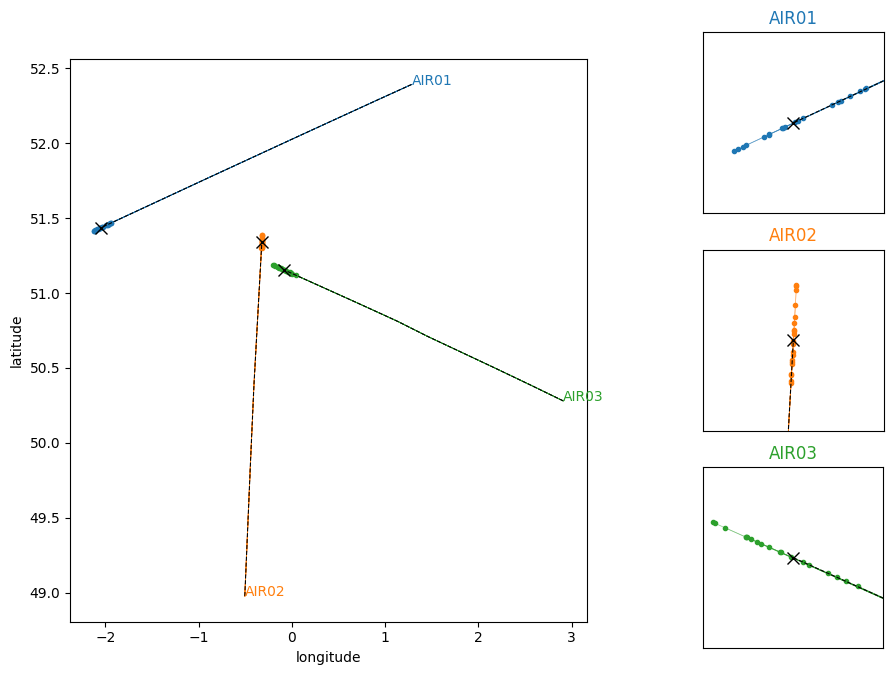

In [5]:
colours = {"AIR01": "tab:blue", "AIR02": "tab:orange", "AIR03": "tab:green"}
window = 0.08  # half the height [deg] of the zoomed views, about 5 nmi

fig, axes = plt.subplot_mosaic(
    [["map", "AIR01"], ["map", "AIR02"], ["map", "AIR03"]], figsize=(11, 8), width_ratios=[2, 1]
)
for _, tracks in runs:
    for callsign, track in tracks.items():
        for ax in (axes["map"], axes[callsign]):
            ax.plot(track[:, 2], track[:, 1], color=colours[callsign], linewidth=0.5, alpha=0.3)
            ax.plot(track[-1, 2], track[-1, 1], "o", color=colours[callsign], markersize=3)
for callsign, track in nominal.items():
    for ax in (axes["map"], axes[callsign]):
        ax.plot(track[:, 2], track[:, 1], "k--", linewidth=0.8)
        ax.plot(track[-1, 2], track[-1, 1], "kx", markersize=8)
    axes["map"].annotate(callsign, (track[0, 2], track[0, 1]), color=colours[callsign])
    # zoom in on where the aircraft is at the end of the baseline run
    lat, lon = track[-1, 1], track[-1, 2]
    axes[callsign].set_ylim(lat - window, lat + window)
    axes[callsign].set_xlim(lon - window / np.cos(np.radians(lat)), lon + window / np.cos(np.radians(lat)))
    axes[callsign].set_xticks([])
    axes[callsign].set_yticks([])
    axes[callsign].set_title(callsign, color=colours[callsign])
for ax in axes.values():
    ax.set_aspect(1 / np.cos(np.radians(51.5)))
axes["map"].set_xlabel("longitude")
axes["map"].set_ylabel("latitude")
plt.show()

The aircraft follow the same routes in every run, so their tracks lie on top of each other. What differs is how far along its route each aircraft has got. Plotting how far each aircraft is ahead of or behind the baseline over time shows how this builds up.

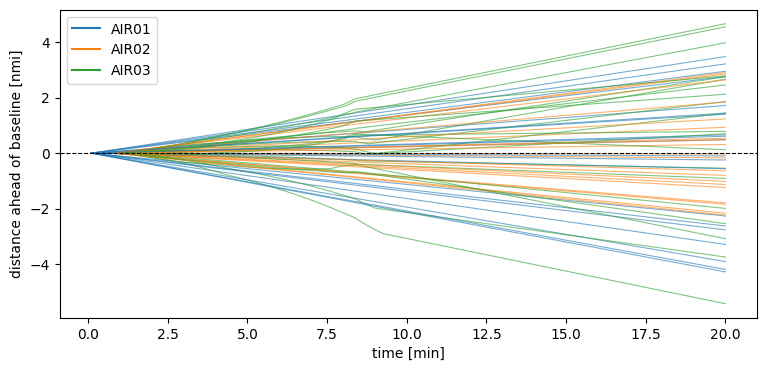

In [6]:
from bluebird_dt.core import Pos2D


def distance_flown(track):
    """Cumulative distance [nmi] flown along a track."""
    points = [Pos2D(lat=lat, lon=lon) for lat, lon in track[:, 1:3]]
    return np.cumsum([0.0] + [a.distance(b) for a, b in zip(points[:-1], points[1:])])


nominal_distance = {callsign: distance_flown(track) for callsign, track in nominal.items()}

fig, ax = plt.subplots(figsize=(9, 4))
for _, tracks in runs:
    for callsign, track in tracks.items():
        ahead = distance_flown(track) - nominal_distance[callsign]
        ax.plot(track[:, 0] / 60, ahead, color=colours[callsign], linewidth=0.8, alpha=0.6)
for callsign, colour in colours.items():
    ax.plot([], [], color=colour, label=callsign)
ax.axhline(0, color="k", linestyle="--", linewidth=0.8)
ax.set_xlabel("time [min]")
ax.set_ylabel("distance ahead of baseline [nmi]")
ax.legend()
plt.show()

The spread grows with time, because each aircraft keeps its percentile rank, and so flies faster or slower than nominal for the whole run. After 20 minutes, the aircraft are up to about 5 nmi ahead of or behind the baseline. `AIR03`'s lines bend between about 7.5 and 9.5 minutes, where it levels off at FL300 in each run.

The next plot shows where this comes from: each aircraft's true air speed at the end of the run, when all three are level, against its speed percentile rank. The dashed lines are the baseline speeds.

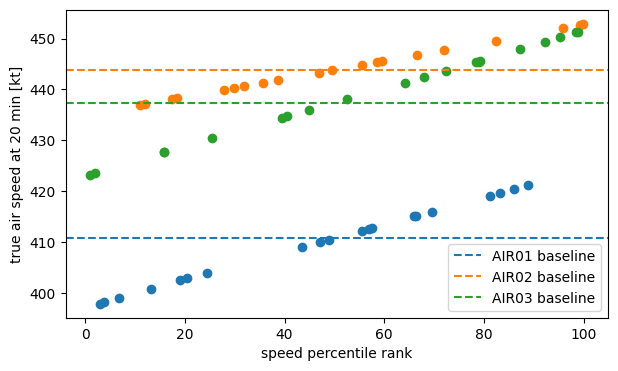

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for ranks, tracks in runs:
    for callsign, track in tracks.items():
        ax.plot(ranks[callsign]["cas_cr"], track[-1, 4], "o", color=colours[callsign])
for callsign, track in nominal.items():
    ax.axhline(track[-1, 4], color=colours[callsign], linestyle="--", label=f"{callsign} baseline")
ax.set_xlabel("speed percentile rank")
ax.set_ylabel("true air speed at 20 min [kt]")
ax.legend()
plt.show()

### Rate of climb

`AIR03`'s climb from FL80 to FL300 shows the second percentile rank at work. Its speed while climbing also depends on the speed rank.

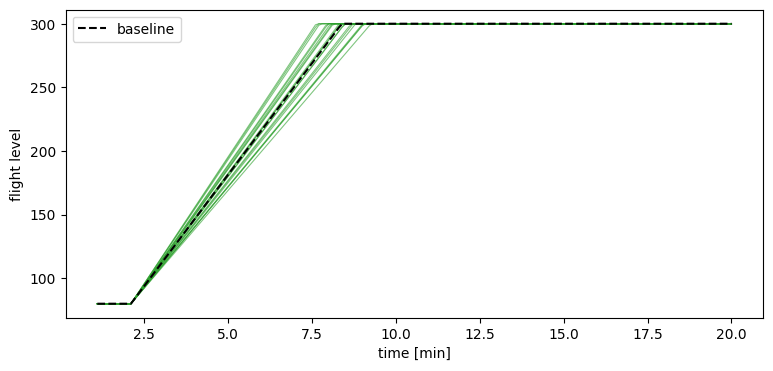

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
for _, tracks in runs:
    track = tracks["AIR03"]
    ax.plot(track[:, 0] / 60, track[:, 3], color=colours["AIR03"], linewidth=0.8, alpha=0.6)
track = nominal["AIR03"]
ax.plot(track[:, 0] / 60, track[:, 3], "k--", label="baseline")
ax.set_xlabel("time [min]")
ax.set_ylabel("flight level")
ax.legend()
plt.show()

## What a fixed seed guarantees

Each run above was seeded, so running it again with the same seed gives exactly the same trajectories:

In [9]:
_, tracks = run_scenario(0)
print(all(np.array_equal(tracks[callsign], runs[0][1][callsign]) for callsign in tracks))

True


A seed fixes each aircraft's percentile ranks, and the predictor adds no randomness of its own. So the same scenario, with the same seeds, the same actions sent at the same times and the same predictor settings, always gives the same trajectories. That lets you compare two agents, or two versions of one, against exactly the same traffic.

## Choosing a predictor

The predictor is set when the simulator is created. Springfield scenarios use `LinearPredictor` unless you pass a different predictor to `from_category`, which is also how to change its settings, such as its internal step `dt`:

In [10]:
from bluebird_dt.predictor import LinearPredictor

predictor = LinearPredictor(dt=1, fix_proximity_threshold=0.5)
sim = Simulator.from_category("Springfield", "example-scenario", predictor=predictor, **log_options)
type(sim.manager.predictor).__name__

'LinearPredictor'

`SimplePredictor` ignores the percentile ranks, so aircraft flown by it don't vary. It can't fly Springfield scenarios, though: it flies each aircraft's selected CAS as its true air speed, and Springfield aircraft don't have one.

## Conclusions

In this notebook we have looked at how `LinearPredictor` varies the performance of each aircraft. Key points are:
* The variation comes from two percentile ranks per aircraft, one for speed and one for rate of climb and descent, drawn from the aircraft's `random_seed` when it is created. The predictor itself is deterministic.
* Springfield scenarios set each aircraft's seed, so they give the same trajectories every run. Calling `randomise_performance` with new seeds gives a spread of trajectories, which grows over time as faster and slower aircraft pull ahead of or fall behind the nominal one.
* `randomise_performance(None)` gives an aircraft the nominal performance.
* The same scenario with the same seeds, actions and predictor settings gives the same trajectories every time.